<a href="https://colab.research.google.com/github/xegor4ikx/labs2/blob/main/%D0%9B%D0%A04_%D0%9C%D0%9D_%D0%A1%D0%B8%D0%BB%D1%96%D0%BD_%D0%84%D0%B3%D0%BE%D1%803_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


In [25]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
TARGET = 'price'

## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [26]:
DATA_FILE = 'CarPrice_Assignment.csv'
DATA_URL = 'https://raw.githubusercontent.com/amankharwal/Website-data/master/CarPrice.csv'
df = pd.read_csv(DATA_FILE if os.path.exists(DATA_FILE) else DATA_URL)

print(f"Кількість об'єктів (рядків): {df.shape[0]}")
print(f"Кількість стовпців: {df.shape[1]}  (з них 1 ідентифікатор car_ID, 1 цільова змінна price, "
      f"{df.shape[1] - 2} ознаки)")
print('\nНазви стовпців:\n', list(df.columns))
display(df.head())

dtypes_info = pd.DataFrame({'Тип даних': df.dtypes.astype(str)})
print('\nКількість стовпців за типами:', df.dtypes.astype(str).value_counts().to_dict())
display(dtypes_info.T)

print(f'\nЦільова змінна: {TARGET} — ціна автомобіля (неперервна числова величина, USD).')

print('\nОсновні статистичні характеристики числових стовпців:')
display(df.describe().T)
print('Основні характеристики категоріальних стовпців:')
display(df.select_dtypes(exclude='number').describe().T)

Кількість об'єктів (рядків): 205
Кількість стовпців: 26  (з них 1 ідентифікатор car_ID, 1 цільова змінна price, 24 ознаки)

Назви стовпців:
 ['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.600,168.800,64.100,48.800,2548,dohc,four,130,mpfi,3.470,2.680,9.000,111,5000,21,27,"13,495.000"
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.600,168.800,64.100,48.800,2548,dohc,four,130,mpfi,3.470,2.680,9.000,111,5000,21,27,"16,500.000"
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.500,171.200,65.500,52.400,2823,ohcv,six,152,mpfi,2.680,3.470,9.000,154,5000,19,26,"16,500.000"
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.800,176.600,66.200,54.300,2337,ohc,four,109,mpfi,3.190,3.400,10.000,102,5500,24,30,"13,950.000"
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.400,176.600,66.400,54.300,2824,ohc,five,136,mpfi,3.190,3.400,8.000,115,5500,18,22,"17,450.000"



Кількість стовпців за типами: {'object': 10, 'int64': 8, 'float64': 8}


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
Тип даних,int64,int64,object,object,object,object,object,object,object,float64,float64,float64,float64,int64,object,object,int64,object,float64,float64,float64,int64,int64,int64,int64,float64



Цільова змінна: price — ціна автомобіля (неперервна числова величина, USD).

Основні статистичні характеристики числових стовпців:


,count,mean,std,min,25%,50%,75%,max
car_ID,205.000,103.000,59.323,1.000,52.000,103.000,154.000,205.000
symboling,205.000,0.834,1.245,-2.000,0.000,1.000,2.000,3.000
wheelbase,205.000,98.757,6.022,86.600,94.500,97.000,102.400,120.900
carlength,205.000,174.049,12.337,141.100,166.300,173.200,183.100,208.100
carwidth,205.000,65.908,2.145,60.300,64.100,65.500,66.900,72.300
carheight,205.000,53.725,2.444,47.800,52.000,54.100,55.500,59.800
curbweight,205.000,"2,555.566",520.680,"1,488.000","2,145.000","2,414.000","2,935.000","4,066.000"
enginesize,205.000,126.907,41.643,61.000,97.000,120.000,141.000,326.000
boreratio,205.000,3.330,0.271,2.540,3.150,3.310,3.580,3.940
stroke,205.000,3.255,0.314,2.070,3.110,3.290,3.410,4.170


Основні характеристики категоріальних стовпців:


,count,unique,top,freq
CarName,205,147,peugeot 504,6
fueltype,205,2,gas,185
aspiration,205,2,std,168
doornumber,205,2,four,115
carbody,205,5,sedan,96
drivewheel,205,3,fwd,120
enginelocation,205,2,front,202
enginetype,205,7,ohc,148
cylindernumber,205,7,four,159
fuelsystem,205,8,mpfi,94


**Висновок до п. 1.** Датасет містить **205 об'єктів** і **26 стовпців**: ідентифікатор `car_ID`, цільову змінну `price` і 24 ознаки. Числових стовпців 16 (8 `int64` + 8 `float64`, разом з `car_ID` і `price`), категоріальних (`object`) — 10.

Цільова змінна **`price`** — неперервна величина від 5 118 до 45 400 USD; середнє (13 277) помітно більше за медіану (10 295), отже розподіл ціни правосторонньо асиметричний. Числові ознаки мають дуже різні масштаби (наприклад, `compressionratio` ≈ 10, `curbweight` ≈ 2 556), тому для лінійних моделей і SVR потрібне масштабування. Частина категоріальних ознак сильно незбалансована: `enginelocation` = front у 202 з 205 авто, `fueltype` = gas у 185.


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [27]:
missing = df.isna().sum()
print('Пропущених значень у всьому датасеті:', int(missing.sum()))
print('Стовпці з пропусками:', list(missing[missing > 0].index) or 'немає')

print('\nПовних дублікатів рядків (з урахуванням car_ID):', df.duplicated().sum())
print('car_ID унікальний для кожного рядка:', df['car_ID'].is_unique)
print('Дублікатів за змістовими характеристиками (без car_ID):',
      df.drop(columns='car_ID').duplicated().sum())
tech_dupl = df.drop(columns=['car_ID', 'CarName']).duplicated(keep=False)
print('Рядків з однаковими технічними характеристиками і ціною, але різною назвою (без car_ID і CarName):',
      int(tech_dupl.sum()))
display(df.loc[tech_dupl, ['car_ID', 'CarName', 'carbody', 'enginesize', 'horsepower', 'price']])

nunique = df.nunique().sort_values(ascending=False).rename('Унікальних значень')
display(nunique.to_frame().T)

brand_raw = df['CarName'].str.split().str[0]
print('\nМарки до виправлення:', sorted(brand_raw.unique()))
brand_fix = {'maxda': 'mazda', 'Nissan': 'nissan', 'porcshce': 'porsche',
             'toyouta': 'toyota', 'vokswagen': 'volkswagen', 'vw': 'volkswagen'}
df['brand'] = brand_raw.str.lower().replace({k.lower(): v for k, v in brand_fix.items()})
print('Марки після виправлення:', sorted(df['brand'].unique()))
print('Кількість марок:', df['brand'].nunique())

df = df.drop(columns='CarName')

Пропущених значень у всьому датасеті: 0
Стовпці з пропусками: немає

Повних дублікатів рядків (з урахуванням car_ID): 0
car_ID унікальний для кожного рядка: True
Дублікатів за змістовими характеристиками (без car_ID): 0
Рядків з однаковими технічними характеристиками і ціною, але різною назвою (без car_ID і CarName): 2


,car_ID,CarName,carbody,enginesize,horsepower,price
24,25,dodge monaco (sw),hatchback,90,68,"6,229.000"
120,121,plymouth fury iii,hatchback,90,68,"6,229.000"


,car_ID,price,curbweight,CarName,carlength,horsepower,wheelbase,carheight,carwidth,enginesize,boreratio,stroke,compressionratio,highwaympg,citympg,peakrpm,fuelsystem,enginetype,cylindernumber,symboling,carbody,drivewheel,enginelocation,fueltype,aspiration,doornumber
Унікальних значень,205,189,171,147,75,59,53,49,44,44,38,37,32,30,29,23,8,7,7,6,5,3,2,2,2,2



Марки до виправлення: ['Nissan', 'alfa-romero', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'maxda', 'mazda', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porcshce', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'toyouta', 'vokswagen', 'volkswagen', 'volvo', 'vw']
Марки після виправлення: ['alfa-romero', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'mazda', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'volkswagen', 'volvo']
Кількість марок: 22


**Висновок до п. 2.** Пропущених значень немає, повних дублікатів немає — ні з урахуванням `car_ID`, ні без нього. Без `car_ID` і `CarName` збігаються лише 2 рядки (`car_ID` 25 — dodge monaco (sw) і 121 — plymouth fury iii): це різні моделі споріднених марок концерну Chrysler з однаковою технічною базою, а не помилка введення. Тому обидва рядки залишено.

За кількістю унікальних значень: `fueltype`, `aspiration`, `doornumber`, `enginelocation` — бінарні; `symboling` має 6 значень (дискретна ознака); `CarName` має 147 унікальних значень на 205 рядків, тобто майже ідентифікатор. One-Hot кодування такої ознаки дало б ~120 розріджених стовпців, а більшість назв із test не трапилася б у train. Тому `CarName` замінено інформативнішою ознакою **`brand`** (марка). При цьому виправлено 6 помилок написання (`maxda`, `Nissan`, `porcshce`, `toyouta`, `vokswagen`, `vw`), і залишилось 22 марки. Перетворення виконується для кожного рядка окремо і не використовує статистик даних, тому витоку інформації з test немає.


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [28]:
car_ids = df['car_ID'].copy()
data = df.drop(columns='car_ID')

print('car_ID збережено окремо:', car_ids.shape, '| унікальних значень:', car_ids.nunique())
print('car_ID серед стовпців для моделювання:', 'car_ID' in data.columns)

car_ID збережено окремо: (205,) | унікальних значень: 205
car_ID серед стовпців для моделювання: False


**Висновок до п. 3.** Ідентифікатори збережено в окремій змінній `car_ids`, а з таблиці ознак `car_ID` видалено. Отже, моделі його не бачать: порядковий номер запису не пов'язаний з ціною, і модель могла б знайти в ньому лише випадкові закономірності. `car_ID` надалі розділяється разом із даними і використовується тільки для ідентифікації авто в результатах (п. 5, 13, 14).


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


Числові стовпці: ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


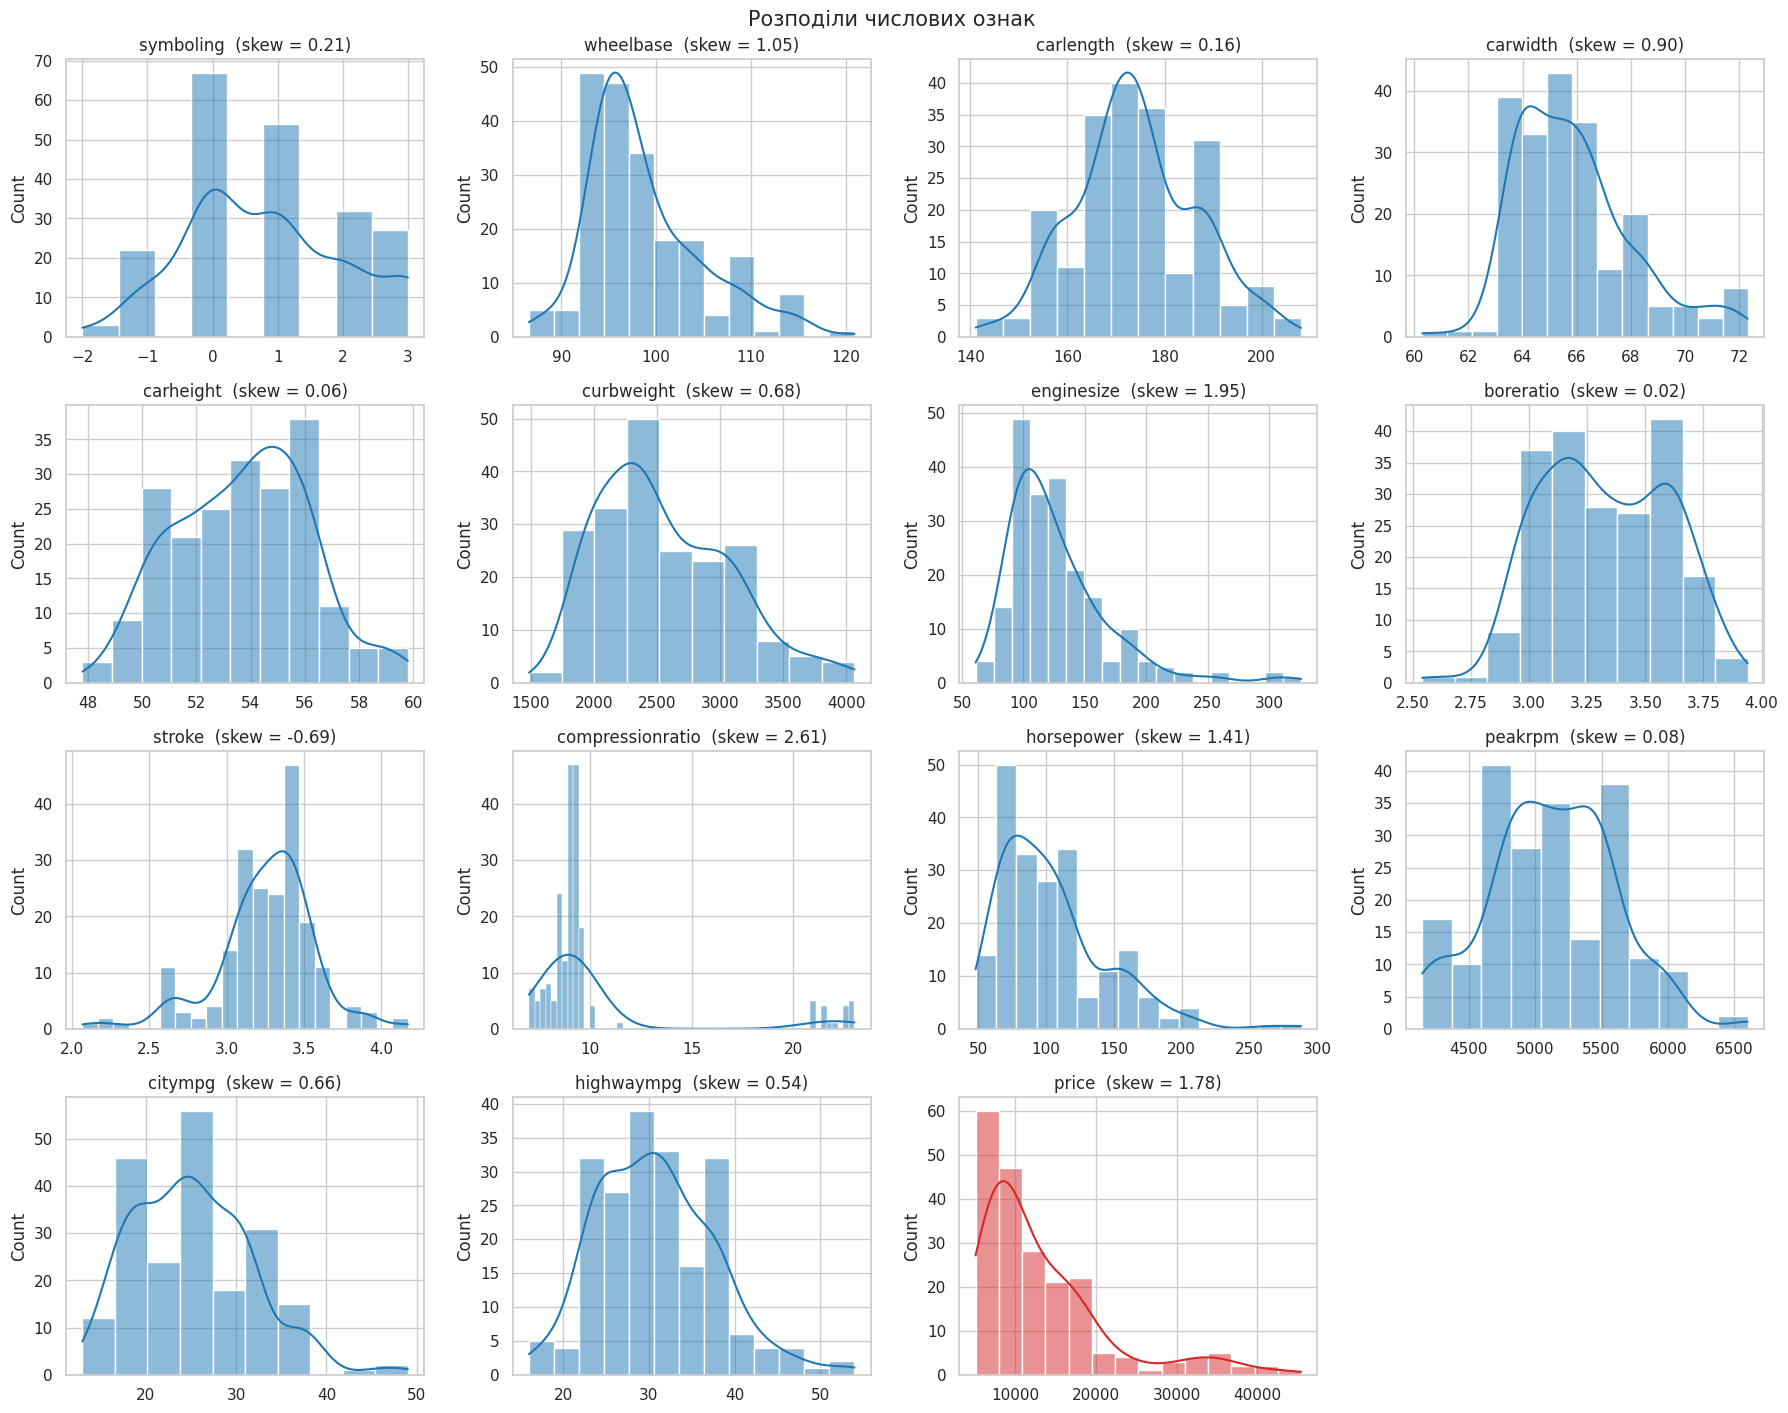

,skew,Асиметрія
compressionratio,2.611,сильна (|s| > 1)
enginesize,1.948,сильна (|s| > 1)
price,1.778,сильна (|s| > 1)
horsepower,1.405,сильна (|s| > 1)
wheelbase,1.050,сильна (|s| > 1)
carwidth,0.904,помірна (0.5 < |s| ≤ 1)
stroke,-0.690,помірна (0.5 < |s| ≤ 1)
curbweight,0.681,помірна (0.5 < |s| ≤ 1)
citympg,0.664,помірна (0.5 < |s| ≤ 1)
highwaympg,0.540,помірна (0.5 < |s| ≤ 1)


Ознаки з найбільш вираженою асиметрією (|skew| > 1): ['compressionratio', 'enginesize', 'price', 'horsepower', 'wheelbase']


In [29]:
num_cols_all = data.select_dtypes(include='number').columns.tolist()
print('Числові стовпці:', num_cols_all)

n_cols = 4
n_rows = int(np.ceil(len(num_cols_all) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.6 * n_rows))
for ax, col in zip(axes.ravel(), num_cols_all):
    sns.histplot(data[col], kde=True, ax=ax, color='tab:blue' if col != TARGET else 'tab:red')
    ax.set_title(f'{col}  (skew = {data[col].skew():.2f})')
    ax.set_xlabel('')
for ax in axes.ravel()[len(num_cols_all):]:
    ax.set_visible(False)
plt.suptitle('Розподіли числових ознак', fontsize=15)
plt.tight_layout()
plt.show()

skew_initial = data[num_cols_all].skew().sort_values(key=np.abs, ascending=False)
skew_table = pd.DataFrame({
    'skew': skew_initial,
    'Асиметрія': pd.cut(skew_initial.abs(), bins=[-np.inf, 0.5, 1, np.inf],
                        labels=['слабка (|s| ≤ 0.5)', 'помірна (0.5 < |s| ≤ 1)', 'сильна (|s| > 1)'])
})
display(skew_table)
print('Ознаки з найбільш вираженою асиметрією (|skew| > 1):',
      list(skew_table.index[skew_initial.abs() > 1]))

**Висновок до п. 4.**
- **Сильна асиметрія (|skew| > 1):** `compressionratio` (2.61), `enginesize` (1.95), `price` (1.78), `horsepower` (1.41), `wheelbase` (1.05). Розподіл `compressionratio` двомодальний: більшість авто мають ступінь стиснення 7–11.5, а окрема група дизельних авто — 21–23. В `enginesize`, `horsepower` і `wheelbase` довгий правий хвіст утворюють великі й потужні автомобілі преміум-сегмента.
- **Помірна асиметрія:** `carwidth` (0.90), `stroke` (−0.69, лівий хвіст), `curbweight` (0.68), `citympg` (0.66), `highwaympg` (0.54).
- **Майже симетричні:** `carlength`, `carheight`, `boreratio`, `peakrpm`, `symboling`.

Цільова змінна також скошена вправо: дешевих авто багато, дорогих — мало, тому найдорожчі автомобілі прогнозувати найважче. Для асиметричних ознак доцільне перетворення Yeo–Johnson, а для довгих хвостів — обробка викидів.


## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [30]:
X = data.drop(columns=TARGET)
y = data[TARGET]

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=RANDOM_STATE
)

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)
print(f'Частка test: {len(X_test) / len(X):.0%}')
print('\ncar_ID у train (перші 10):', id_train.head(10).tolist())
print('car_ID у test  (перші 10):', id_test.head(10).tolist())
print('Перетин car_ID між train і test:', len(set(id_train) & set(id_test)))
print(f'\nСередня ціна: train = {y_train.mean():,.0f}, test = {y_test.mean():,.0f}')

X_train: (164, 24) | X_test: (41, 24)
y_train: (164,) | y_test: (41,)
Частка test: 20%

car_ID у train (перші 10): [67, 112, 154, 97, 39, 25, 140, 113, 30, 20]
car_ID у test  (перші 10): [16, 10, 101, 133, 69, 96, 160, 163, 148, 183]
Перетин car_ID між train і test: 0

Середня ціна: train = 13,223, test = 13,490


**Висновок до п. 5.** Дані розділено на **164 об'єкти train** (80%) і **41 об'єкт test** (20%). `random_state=42` забезпечує відтворюваність поділу. `car_ID` розділено синхронно з ознаками (`id_train`, `id_test`), і перетину між вибірками немає. Середня ціна в train (13 223) і test (13 490) близька, тож поділ репрезентативний. Усі наступні параметри передобробки визначаються лише за train.


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


Неперервні числові ознаки: ['wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']


,Нижня межа,Верхня межа,Викидів у train,% у train,Викидів у test (межі train)
compressionratio,7.400,10.600,20,12.200,8
stroke,2.660,3.860,16,9.800,4
carwidth,60.425,70.425,10,6.100,2
horsepower,4.750,182.750,7,4.300,1
enginesize,33.500,205.500,7,4.300,3
wheelbase,83.100,113.500,6,3.700,1
peakrpm,"3,750.000","6,550.000",2,1.200,0
highwaympg,11.500,47.500,1,0.600,2
boreratio,2.565,4.125,1,0.600,0
curbweight,998.625,"4,103.625",0,0.000,0


Рядків train, що містять хоча б один викид: 50 з 164 (30%) — видаляти їх недоцільно.
Викидів у train після обмеження: 0 | у test після обмеження: 0


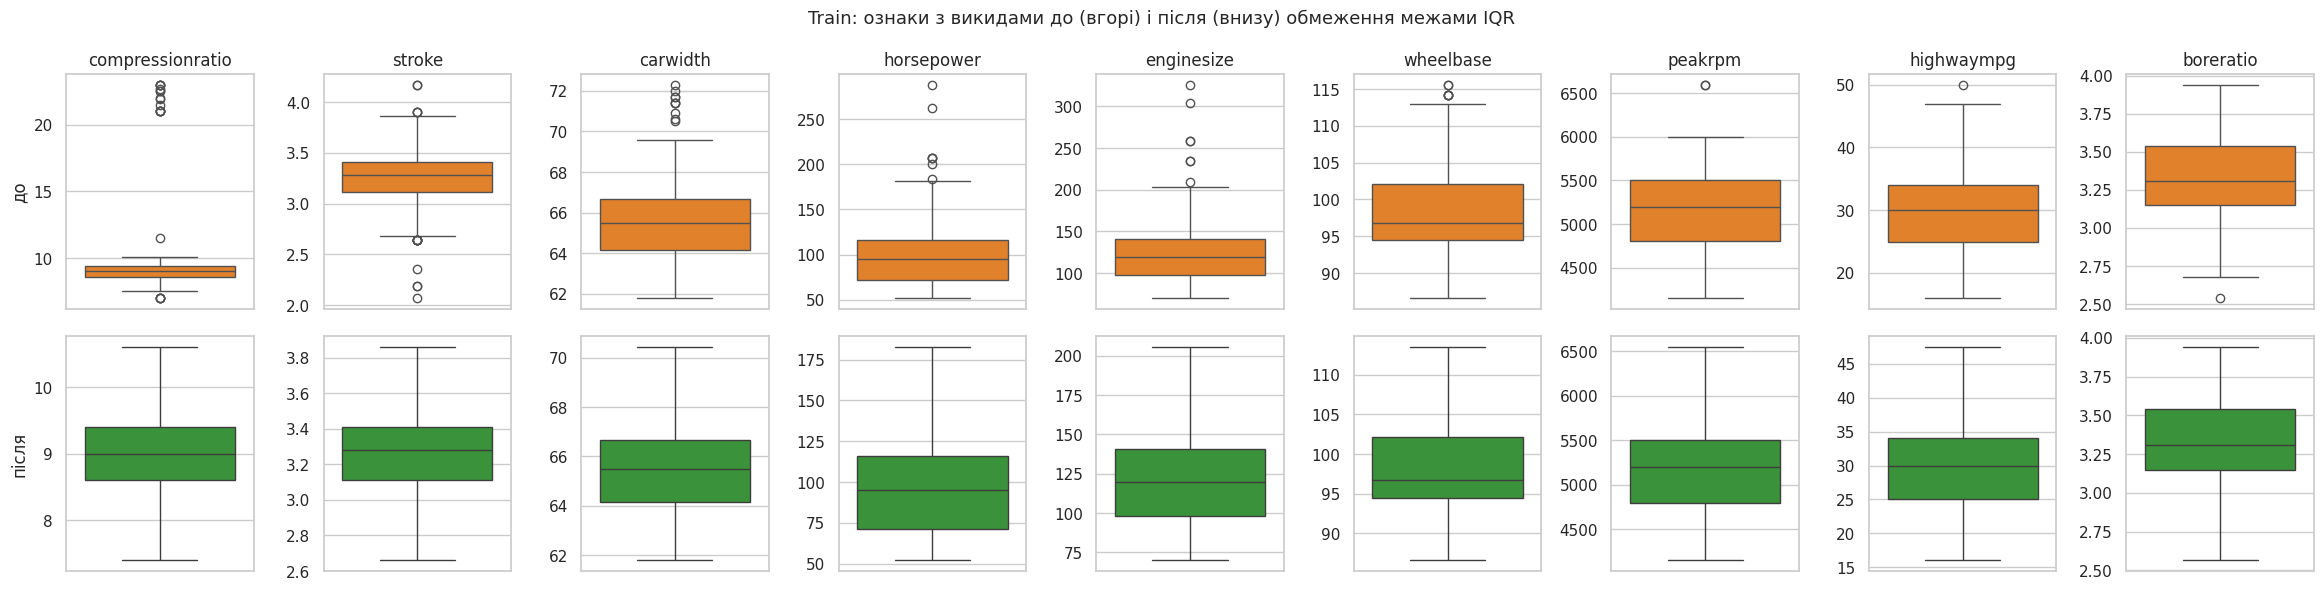

In [31]:
DISCRETE_FEATURES = ['symboling']
cont_features = [c for c in X_train.select_dtypes(include='number').columns
                 if c not in DISCRETE_FEATURES]
print('Неперервні числові ознаки:', cont_features)


class IQRClipper(BaseEstimator, TransformerMixin):
    """Обмежує значення межами [Q1 - k*IQR, Q3 + k*IQR], обчисленими під час fit (тобто за train)."""

    def __init__(self, k=1.5):
        self.k = k

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        q1, q3 = X_df.quantile(0.25), X_df.quantile(0.75)
        iqr = q3 - q1
        self.lower_ = (q1 - self.k * iqr).to_numpy()
        self.upper_ = (q3 + self.k * iqr).to_numpy()
        self.feature_names_in_ = np.asarray(X_df.columns, dtype=object)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        return X_df.clip(lower=self.lower_, upper=self.upper_, axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.feature_names_in_ if input_features is None else input_features, dtype=object)


clipper = IQRClipper(k=1.5).fit(X_train[cont_features])
bounds = pd.DataFrame({'Нижня межа': clipper.lower_, 'Верхня межа': clipper.upper_}, index=cont_features)


def count_outliers(X_part):
    return ((X_part[cont_features] < bounds['Нижня межа']) | (X_part[cont_features] > bounds['Верхня межа'])).sum()


outlier_table = bounds.assign(
    **{'Викидів у train': count_outliers(X_train),
       '% у train': (count_outliers(X_train) / len(X_train) * 100).round(1),
       'Викидів у test (межі train)': count_outliers(X_test)}
).sort_values('Викидів у train', ascending=False)
display(outlier_table)
rows_with_outliers = ((X_train[cont_features] < bounds['Нижня межа']) |
                      (X_train[cont_features] > bounds['Верхня межа'])).any(axis=1).sum()
print(f'Рядків train, що містять хоча б один викид: {rows_with_outliers} з {len(X_train)} '
      f'({rows_with_outliers / len(X_train):.0%}) — видаляти їх недоцільно.')

X_train_clip = X_train.copy()
X_test_clip = X_test.copy()
X_train_clip[cont_features] = clipper.transform(X_train[cont_features]).to_numpy()
X_test_clip[cont_features] = clipper.transform(X_test[cont_features]).to_numpy()
print('Викидів у train після обмеження:', int(count_outliers(X_train_clip).sum()),
      '| у test після обмеження:', int(count_outliers(X_test_clip).sum()))

feat_with_out = outlier_table.index[outlier_table['Викидів у train'] > 0].tolist()
fig, axes = plt.subplots(2, len(feat_with_out), figsize=(2.6 * len(feat_with_out), 6))
for i, col in enumerate(feat_with_out):
    sns.boxplot(y=X_train[col], ax=axes[0, i], color='tab:orange')
    sns.boxplot(y=X_train_clip[col], ax=axes[1, i], color='tab:green')
    axes[0, i].set_title(col)
    axes[0, i].set_ylabel('до' if i == 0 else '')
    axes[1, i].set_ylabel('після' if i == 0 else '')
plt.suptitle('Train: ознаки з викидами до (вгорі) і після (внизу) обмеження межами IQR', fontsize=13)
plt.tight_layout()
plt.show()

**Висновок і обґрунтування обробки викидів (п. 6).** За правилом IQR (межі Q1 − 1.5·IQR, Q3 + 1.5·IQR, обчислені тільки за train, без `price`) потенційні викиди мають 9 з 13 неперервних ознак:
- найбільше у `compressionratio` — 20 (12.2%); це дизельні авто зі ступенем стиснення 21–23, тобто природна група, а не помилки. Інформацію про тип палива зберігає ознака `fueltype`;
- `stroke` — 16, `carwidth` — 10, `horsepower` і `enginesize` — по 7; у двох останніх це реальні потужні дорогі автомобілі.

Хоча б один викид містять **50 із 164 рядків train (30%)**. Видалення таких рядків скоротило б і без того малу вибірку майже на третину і прибрало б саме дорогі авто, які модель має навчитися прогнозувати. Тому викиди **не видаляються**, а **обмежуються межами train (clipping / вінзоризація)**. Так зберігаються всі спостереження, а вплив екстремальних значень на лінійні моделі та SVR зменшується. До test застосовано ті самі межі (у test їх перевищували, зокрема, 8 значень `compressionratio`). Ціну не обмежували. Цей самий крок `IQRClipper` включено першим етапом передобробки в Pipeline (п. 8), тому в моделях межі також визначаються тільки за train.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


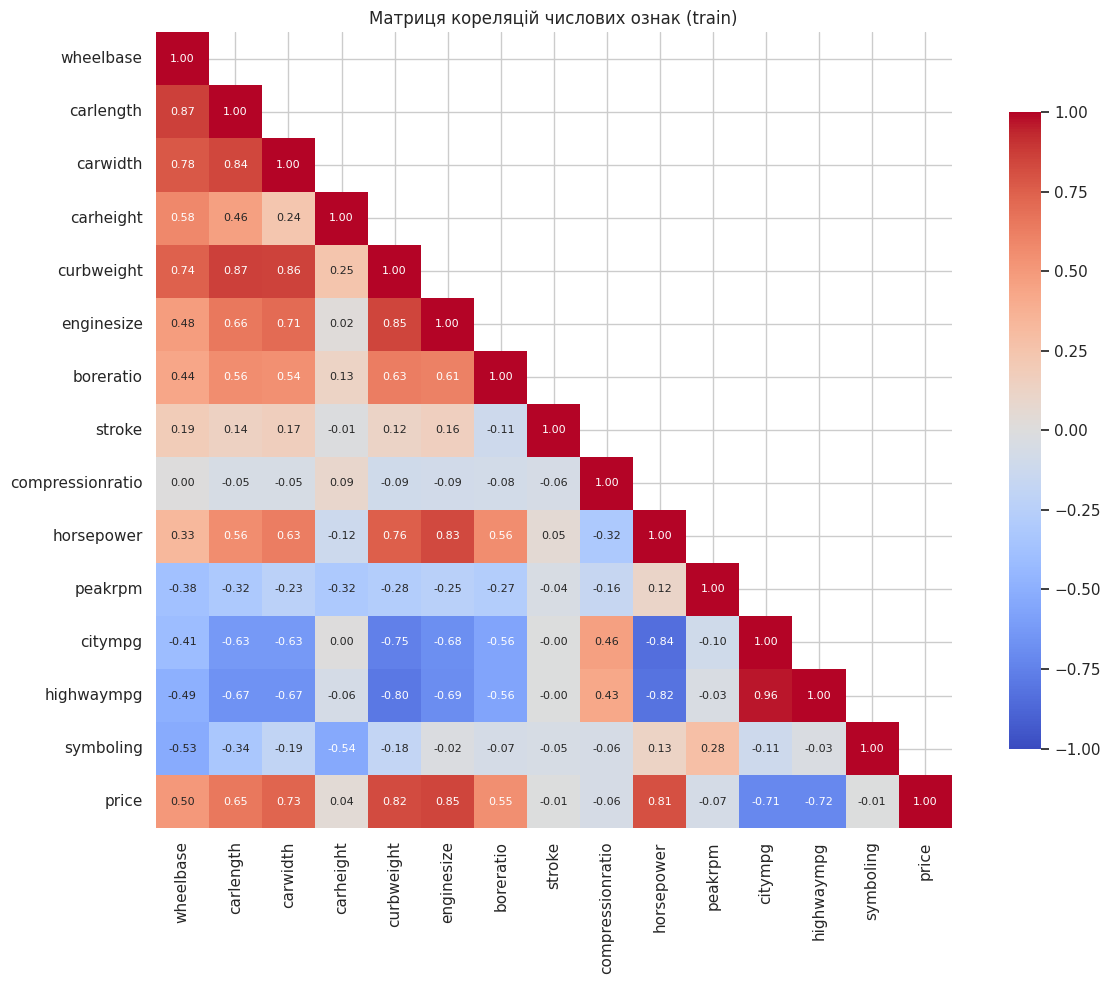

Сильно корельовані пари (|r| > 0.85):


,Ознака 1,Ознака 2,r,"|r(ознака 1, price)|","|r(ознака 2, price)|",Рішення
0,citympg,highwaympg,0.964,0.711,0.716,видалити citympg
1,wheelbase,carlength,0.867,0.504,0.652,видалити wheelbase
2,carlength,curbweight,0.866,0.652,0.824,видалити carlength
3,carwidth,curbweight,0.858,0.732,0.824,видалити carwidth


Ознаки, які видаляються: ['carlength', 'carwidth', 'citympg', 'wheelbase']
X_train: (164, 20) | X_test: (41, 20)
Неперервні ознаки, що залишились: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']


In [32]:
CORR_THRESHOLD = 0.85
num_features = cont_features + DISCRETE_FEATURES
corr_df = X_train_clip[num_features].assign(price=y_train)
corr_matrix = corr_df.corr()

plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, annot_kws={'size': 8}, square=True, cbar_kws={'shrink': 0.8})
plt.title('Матриця кореляцій числових ознак (train)')
plt.tight_layout()
plt.show()

corr_with_price = corr_matrix[TARGET].drop(TARGET).abs()

pairs = []
for i, f1 in enumerate(num_features):
    for f2 in num_features[i + 1:]:
        r = corr_matrix.loc[f1, f2]
        if abs(r) > CORR_THRESHOLD:
            pairs.append((f1, f2, r))
pairs.sort(key=lambda p: abs(p[2]), reverse=True)

to_drop, rows = set(), []
for f1, f2, r in pairs:
    if f1 in to_drop or f2 in to_drop:
        decision = 'пара вже розв\'язана (одна з ознак видалена раніше)'
    else:
        weaker = f1 if corr_with_price[f1] < corr_with_price[f2] else f2
        to_drop.add(weaker)
        decision = f'видалити {weaker}'
    rows.append({'Ознака 1': f1, 'Ознака 2': f2, 'r': r,
                 '|r(ознака 1, price)|': corr_with_price[f1],
                 '|r(ознака 2, price)|': corr_with_price[f2], 'Рішення': decision})

print(f'Сильно корельовані пари (|r| > {CORR_THRESHOLD}):')
display(pd.DataFrame(rows))
features_to_drop = sorted(to_drop)
print('Ознаки, які видаляються:', features_to_drop)

X_train = X_train.drop(columns=features_to_drop)
X_test = X_test.drop(columns=features_to_drop)
X_train_clip = X_train_clip.drop(columns=features_to_drop)
X_test_clip = X_test_clip.drop(columns=features_to_drop)
cont_features = [c for c in cont_features if c not in features_to_drop]
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Неперервні ознаки, що залишились:', cont_features)

**Висновок до п. 7.** У train знайдено 4 пари ознак з |r| > 0.85. Пари оброблялись від найсильнішої кореляції, і в кожній залишалась ознака, тісніше пов'язана з `price`:

| Пара | r | \|r\| з price | Видалено |
|---|---|---|---|
| citympg – highwaympg | 0.96 | 0.711 / 0.716 | `citympg` |
| wheelbase – carlength | 0.87 | 0.50 / 0.65 | `wheelbase` |
| carlength – curbweight | 0.87 | 0.65 / 0.82 | `carlength` |
| carwidth – curbweight | 0.86 | 0.73 / 0.82 | `carwidth` |

Видалено **`citympg`, `wheelbase`, `carlength`, `carwidth`**: вони дублюють інформацію про розмір і витрату пального, яку зберігають `curbweight` (найсильніший зв'язок з ціною серед розмірних ознак, r = 0.82) і `highwaympg`. Пара `enginesize`–`curbweight` (r = 0.849) поріг не перевищує, тому обидві ознаки залишено. Із test видалено ті самі 4 ознаки, рішення ухвалено лише за train. Залишилось 20 ознак: 9 неперервних, `symboling` і 10 категоріальних.


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [33]:
cat_features = X_train.select_dtypes(exclude='number').columns.tolist()
print('Неперервні числові ознаки:', cont_features)
print('Дискретна числова ознака:', DISCRETE_FEATURES)
print('Категоріальні ознаки:', cat_features)

continuous_pipe = Pipeline([
    ('clip', IQRClipper(k=1.5)),
    ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scaler', StandardScaler()),
])
discrete_pipe = Pipeline([('scaler', StandardScaler())])
categorical_pipe = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('cont', continuous_pipe, cont_features),
    ('disc', discrete_pipe, DISCRETE_FEATURES),
    ('cat', categorical_pipe, cat_features),
], remainder='drop')

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print('\nРозмірність після передобробки: train', X_train_prep.shape, '| test', X_test_prep.shape)
print('Кількість ознак після One-Hot Encoding:', len(feature_names))

unseen = {c: sorted(set(X_test[c]) - set(X_train[c])) for c in cat_features}
unseen = {c: v for c, v in unseen.items() if v}
print('Категорії test, яких немає у train:', unseen if unseen else 'немає')
for col, values in unseen.items():
    ohe_cols = [i for i, n in enumerate(feature_names) if n.startswith(f'cat__{col}_')]
    mask_rows = X_test[col].isin(values).to_numpy()
    print(f'  {col}={values}: рядків у test — {mask_rows.sum()}, '
          f'сума їх one-hot значень по {col} = {X_test_prep[mask_rows][:, ohe_cols].sum():.0f} '
          f'(закодовано нулями, помилки немає)')

Неперервні числові ознаки: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна числова ознака: ['symboling']
Категоріальні ознаки: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']

Розмірність після передобробки: train (164, 69) | test (41, 69)
Кількість ознак після One-Hot Encoding: 69
Категорії test, яких немає у train: {'cylindernumber': ['three']}
  cylindernumber=['three']: рядків у test — 1, сума їх one-hot значень по cylindernumber = 0 (закодовано нулями, помилки немає)


**Висновок до п. 8.** Ознаки розділено на три групи, кожна обробляється у своїй гілці `ColumnTransformer`:
- **9 неперервних:** обмеження викидів межами IQR → Yeo–Johnson → StandardScaler;
- **`symboling`:** лише StandardScaler (дискретна порядкова шкала від −2 до 3, Yeo–Johnson не застосовується);
- **10 категоріальних:** One-Hot Encoding з `handle_unknown='ignore'`.

Після передобробки виходить 69 ознак. У test трапилась категорія `cylindernumber = 'three'` (1 авто, Chevrolet), якої немає в train. Вона закодована нулями, тож помилки не виникає. Увесь механізм навчається лише на `X_train` (`fit`), а test тільки трансформується (`transform`). Оскільки передобробка входить у Pipeline кожної моделі, під час крос-валідації вона перенавчається окремо на кожному фолді, і витоку даних немає.


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


,skew до,skew після обмеження викидів,skew після clip + Yeo–Johnson + StandardScaler,|skew| зменшився
compressionratio,2.737,0.056,0.005,True
enginesize,2.050,0.962,0.045,True
horsepower,1.546,0.851,0.066,True
stroke,-0.755,-0.398,0.016,True
curbweight,0.712,0.712,0.050,True
highwaympg,0.290,0.244,-0.012,True
peakrpm,0.067,0.040,-0.004,True
boreratio,0.050,0.063,-0.006,True
carheight,0.028,0.028,-0.005,True


Середній |skew| до: 0.915 | після: 0.023
Ознак з |skew| > 1 до: 3 | після: 0
Після StandardScaler: середні ≈ 0.0 , стандартні відхилення ≈ [1.]


,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,highwaympg
λ Yeo–Johnson,0.677,-0.841,-0.901,0.461,2.888,0.804,-0.632,0.842,0.484


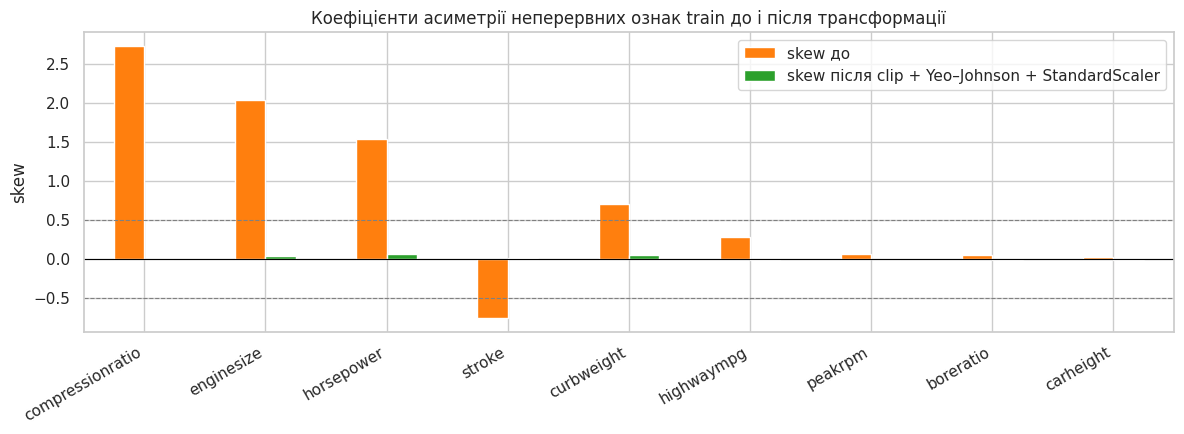

In [34]:
cont_transformer = preprocessor.named_transformers_['cont']
X_train_cont_transformed = pd.DataFrame(cont_transformer.transform(X_train[cont_features]),
                                        columns=cont_features, index=X_train.index)

skew_compare = pd.DataFrame({
    'skew до': X_train[cont_features].skew(),
    'skew після обмеження викидів': X_train_clip[cont_features].skew(),
    'skew після clip + Yeo–Johnson + StandardScaler': X_train_cont_transformed.skew(),
})
skew_compare['|skew| зменшився'] = (skew_compare.iloc[:, 2].abs() < skew_compare.iloc[:, 0].abs())
skew_compare = skew_compare.sort_values('skew до', key=np.abs, ascending=False)
display(skew_compare)
print('Середній |skew| до:', round(skew_compare['skew до'].abs().mean(), 3),
      '| після:', round(skew_compare.iloc[:, 2].abs().mean(), 3))
print('Ознак з |skew| > 1 до:', int((skew_compare['skew до'].abs() > 1).sum()),
      '| після:', int((skew_compare.iloc[:, 2].abs() > 1).sum()))
print('Після StandardScaler: середні ≈', round(float(X_train_cont_transformed.mean().abs().max()), 6),
      ', стандартні відхилення ≈', X_train_cont_transformed.std(ddof=0).round(3).unique())

lambdas = pd.Series(cont_transformer.named_steps['yeo_johnson'].lambdas_, index=cont_features, name='λ Yeo–Johnson')
display(lambdas.to_frame().T)

skew_compare.iloc[:, [0, 2]].plot(kind='bar', figsize=(12, 4.5), color=['tab:orange', 'tab:green'])
plt.axhline(0, color='black', lw=0.8)
plt.axhline(0.5, color='gray', ls='--', lw=0.8)
plt.axhline(-0.5, color='gray', ls='--', lw=0.8)
plt.title('Коефіцієнти асиметрії неперервних ознак train до і після трансформації')
plt.ylabel('skew')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

**Висновок до п. 9.** Трансформація неперервних ознак виявилась ефективною. Середній |skew| знизився з **0.915 до 0.023**, а кількість ознак із сильною асиметрією (|skew| > 1) — з 3 до 0. Найбільше змінились `compressionratio` (2.74 → 0.005), `enginesize` (2.05 → 0.045), `horsepower` (1.55 → 0.066) і `stroke` (−0.76 → 0.016). Значення skew «до» трохи відрізняються від п. 4, бо тут вони обчислені лише за train.

Одне обмеження викидів асиметрію зменшує, але не усуває (у `enginesize` залишається 0.96, у `horsepower` — 0.85). Майже симетричними розподіли робить саме Yeo–Johnson. Параметри λ < 1 (`curbweight` −0.84, `enginesize` −0.90, `horsepower` −0.63) «стискають» правий хвіст подібно до логарифма, а λ = 2.89 для `stroke` виправляє лівосторонню асиметрію. StandardScaler форму розподілу не змінює, але приводить ознаки до середнього 0 і стандартного відхилення 1.


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [35]:
from sklearn.base import clone

regressors = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=10.0, max_iter=100_000),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                   random_state=RANDOM_STATE),
    'SVR': TransformedTargetRegressor(regressor=SVR(kernel='rbf', C=10, epsilon=0.05),
                                      transformer=StandardScaler()),
}

pipelines = {name: Pipeline([('preprocessing', clone(preprocessor)), ('model', model)])
             for name, model in regressors.items()}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f'{name:<18} навчено')

pipelines['Random Forest']

Linear Regression  навчено
Ridge Regression   навчено
Lasso Regression   навчено
Random Forest      навчено
Gradient Boosting  навчено
SVR                навчено


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('cont',
                                                  Pipeline(steps=[('clip',
                                                                   IQRClipper()),
                                                                  ('yeo_johnson',
                                                                   PowerTransformer(standardize=False)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['carheight', 'curbweight',
                                                   'enginesize', 'boreratio',
                                                   'stroke', 'compressionratio',
                                                   'horsepower', 'peakrpm',
                                                   'highwaympg']),
                                                 ('disc',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['symboling']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['fueltype', 'aspiration',
                                                   'doornumber', 'carbody',
                                                   'drivewheel',
                                                   'enginelocation',
                                                   'enginetype',
                                                   'cylindernumber',
                                                   'fuelsystem', 'brand'])])),
                ('model',
                 RandomForestRegressor(n_estimators=300, n_jobs=-1,
                                       random_state=42))])

**Висновок до п. 10.** Побудовано 6 Pipeline з **однаковою** передобробкою (копія `preprocessor`) і різними моделями:
- `LinearRegression`;
- `Ridge(alpha=1)`;
- `Lasso(alpha=10)` зі збільшеним `max_iter` для збіжності;
- `RandomForest` (300 дерев);
- `GradientBoosting` (300 дерев, learning_rate = 0.05, max_depth = 3);
- `SVR` (RBF-ядро, C = 10, ε = 0.05).

Для SVR ціну додатково стандартизовано через `TransformedTargetRegressor`, бо ε задається в одиницях цільової змінної, і без масштабування `price` (тисячі USD) модель практично не навчається. Прогнози при цьому автоматично повертаються в USD, а підготовка ознак X для всіх моделей однакова. Для ансамблів зафіксовано `random_state=42`.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


Метрики на тестовій вибірці (впорядковано за R²). Основні: R², MAE, MSE, MAPE;
додатково: RMSE і R² на train / крос-валідації для аналізу перенавчання.


,Модель,R²,MAE,MSE,"MAPE, %",RMSE,R² train,"R² CV (5 fold, train)",Різниця R² train − test
1,Random Forest,0.9554,"1,311","3,519,785",9.64,"1,876",0.9851,0.8828,0.0297
2,SVR,0.9340,"1,603","5,211,151",14.07,"2,283",0.9920,0.8716,0.0580
3,Gradient Boosting,0.9311,"1,689","5,442,891",11.46,"2,333",0.9957,0.8863,0.0646
4,Linear Regression,0.8794,"2,156","9,518,236",16.38,"3,085",0.9597,0.8272,0.0803
5,Ridge Regression,0.8538,"2,367","11,542,488",18.19,"3,397",0.9482,0.8637,0.0944
6,Lasso Regression,0.8504,"2,350","11,807,240",17.38,"3,436",0.9529,0.8668,0.1025


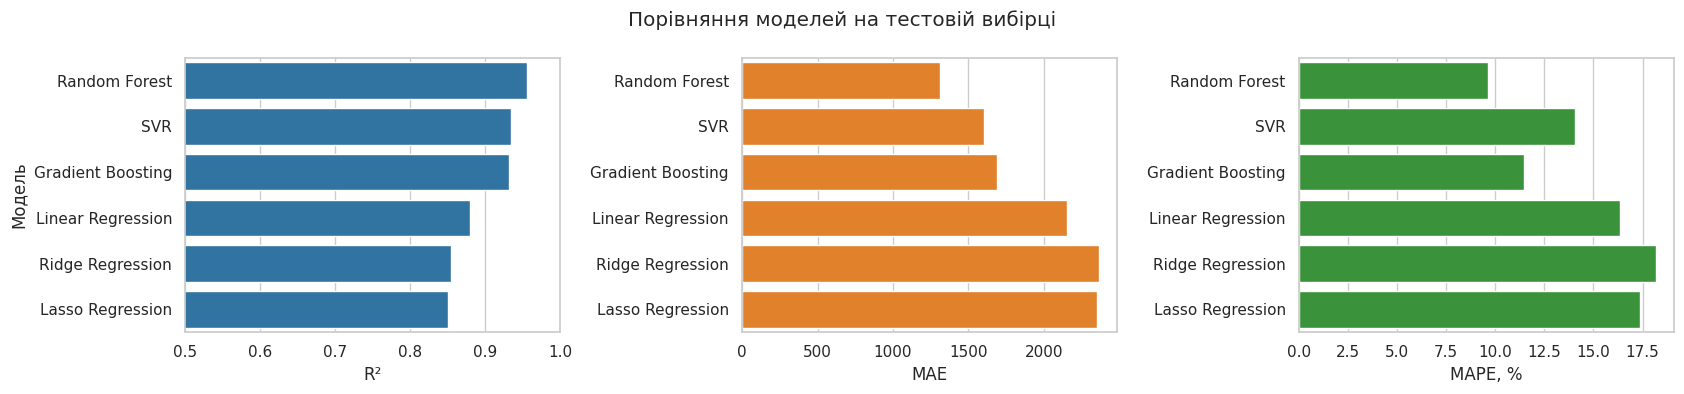

In [36]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, predictions = [], {}

for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred
    cv_r2 = cross_val_score(clone(pipe), X_train, y_train, cv=cv, scoring='r2')
    results.append({
        'Модель': name,
        'R²': r2_score(y_test, y_pred),
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred),
        'MAPE, %': mean_absolute_percentage_error(y_test, y_pred) * 100,
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R² train': r2_score(y_train, pipe.predict(X_train)),
        'R² CV (5 fold, train)': cv_r2.mean(),
    })

results_df = (pd.DataFrame(results).sort_values('R²', ascending=False)
              .reset_index(drop=True))
results_df.index += 1
results_df['Різниця R² train − test'] = results_df['R² train'] - results_df['R²']

print('Метрики на тестовій вибірці (впорядковано за R²). Основні: R², MAE, MSE, MAPE;')
print('додатково: RMSE і R² на train / крос-валідації для аналізу перенавчання.')
display(results_df.style.format({
    'R²': '{:.4f}', 'MAE': '{:,.0f}', 'MSE': '{:,.0f}', 'MAPE, %': '{:.2f}', 'RMSE': '{:,.0f}',
    'R² train': '{:.4f}', 'R² CV (5 fold, train)': '{:.4f}', 'Різниця R² train − test': '{:.4f}'
}).highlight_max(subset=['R²'], color='lightgreen')
  .highlight_min(subset=['MAE', 'MSE', 'MAPE, %'], color='lightgreen'))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
order = results_df['Модель']
sns.barplot(data=results_df, y='Модель', x='R²', ax=axes[0], order=order, color='tab:blue')
sns.barplot(data=results_df, y='Модель', x='MAE', ax=axes[1], order=order, color='tab:orange')
sns.barplot(data=results_df, y='Модель', x='MAPE, %', ax=axes[2], order=order, color='tab:green')
axes[0].set_xlim(min(0.5, results_df['R²'].min() - 0.05), 1)
for ax in axes[1:]:
    ax.set_ylabel('')
plt.suptitle('Порівняння моделей на тестовій вибірці')
plt.tight_layout()
plt.show()

**Висновок до п. 11.**
- **Найкращий результат за всіма чотирма метриками має Random Forest:** R² = 0.955, MAE ≈ 1 311 USD, MSE ≈ 3.52 млн, MAPE ≈ 9.6%.
- **Далі йдуть SVR і Gradient Boosting:** R² = 0.934 і 0.931. SVR має трохи менші MAE і MSE, але більшу MAPE (14.1% проти 11.5%), тобто частіше помиляється у відносному вимірі на дешевих авто.
- **Лінійні моделі помітно слабші:** R² 0.85–0.88, MAE 2.2–2.4 тис. USD, MAPE 16–18%. Залежність ціни від характеристик нелінійна і містить взаємодії (марка × двигун), які ансамблі дерев і RBF-ядро враховують, а лінійна модель — ні.
- **Порядок лінійних моделей на test і на CV не збігається.** На test Linear Regression трохи краща за Ridge і Lasso, але на 5-кратній крос-валідації train вона найгірша (R² 0.827 проти 0.864 і 0.867). Регуляризовані моделі стабільніші, а перевага Linear Regression на test пояснюється малим розміром тестової вибірки (41 авто).
- **MSE дуже чутлива до великих помилок.** Одне авто (`car_ID` 17, BMW за 41 315 USD) дає понад 40% MSE кожної лінійної моделі.
- **Ознаки перенавчання помірні.** R² на train для ансамблів і SVR 0.985–0.996, на test 0.93–0.96, різниця 0.03–0.06. У лінійних моделей різниця 0.08–0.10. R² на крос-валідації (0.87–0.89 для найкращих моделей) нижчий за тестовий, тож поточний test дещо «легший», і реалістичну якість на нових даних варто оцінювати на рівні R² ≈ 0.87–0.9.


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


**Пояснення до п. 12.**

**Чому класифікація не підходить.** Logistic Regression — модель **класифікації**. Через сигмоїду (softmax) вона оцінює ймовірність належності об'єкта до одного з **дискретних класів** і повертає мітку класу, а не число. Ціна ж — **неперервна** величина: у датасеті 189 різних значень на 205 авто. Якщо вважати кожну ціну окремим класом:
- більшість «класів» міститимуть по одному об'єкту;
- модель не зможе спрогнозувати ціну, якої не було в train;
- модель ігнорує порядок і відстань між значеннями: помилка в 100 USD і в 20 000 USD для неї однаково «неправильні»;
- метрики класифікації (accuracy тощо) не відображають величину помилки в грошах.

Логістичну регресію можна використати лише після дискретизації ціни на діапазони (дешеві / середні / дорогі), але це вже **інша задача** з втратою інформації.

**Тип задачі.** Прогнозування `price` — задача **регресії** (навчання з учителем із неперервною цільовою змінною): потрібно за ознаками авто передбачити дійсне число. Усі моделі в роботі — регресори, які повертають неперервний прогноз і мінімізують функцію втрат, що враховує величину відхилення:
- Linear, Ridge, Lasso — MSE, у Ridge і Lasso з L2 / L1-регуляризацією;
- Random Forest і Gradient Boosting — дерева регресії з розбиттям за MSE; прогноз — середнє значень у листках (RF) або сума поправок (GB);
- SVR — ε-нечутлива функція втрат.

Тому для їх оцінювання використано регресійні метрики R², MAE, MSE, MAPE.


## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


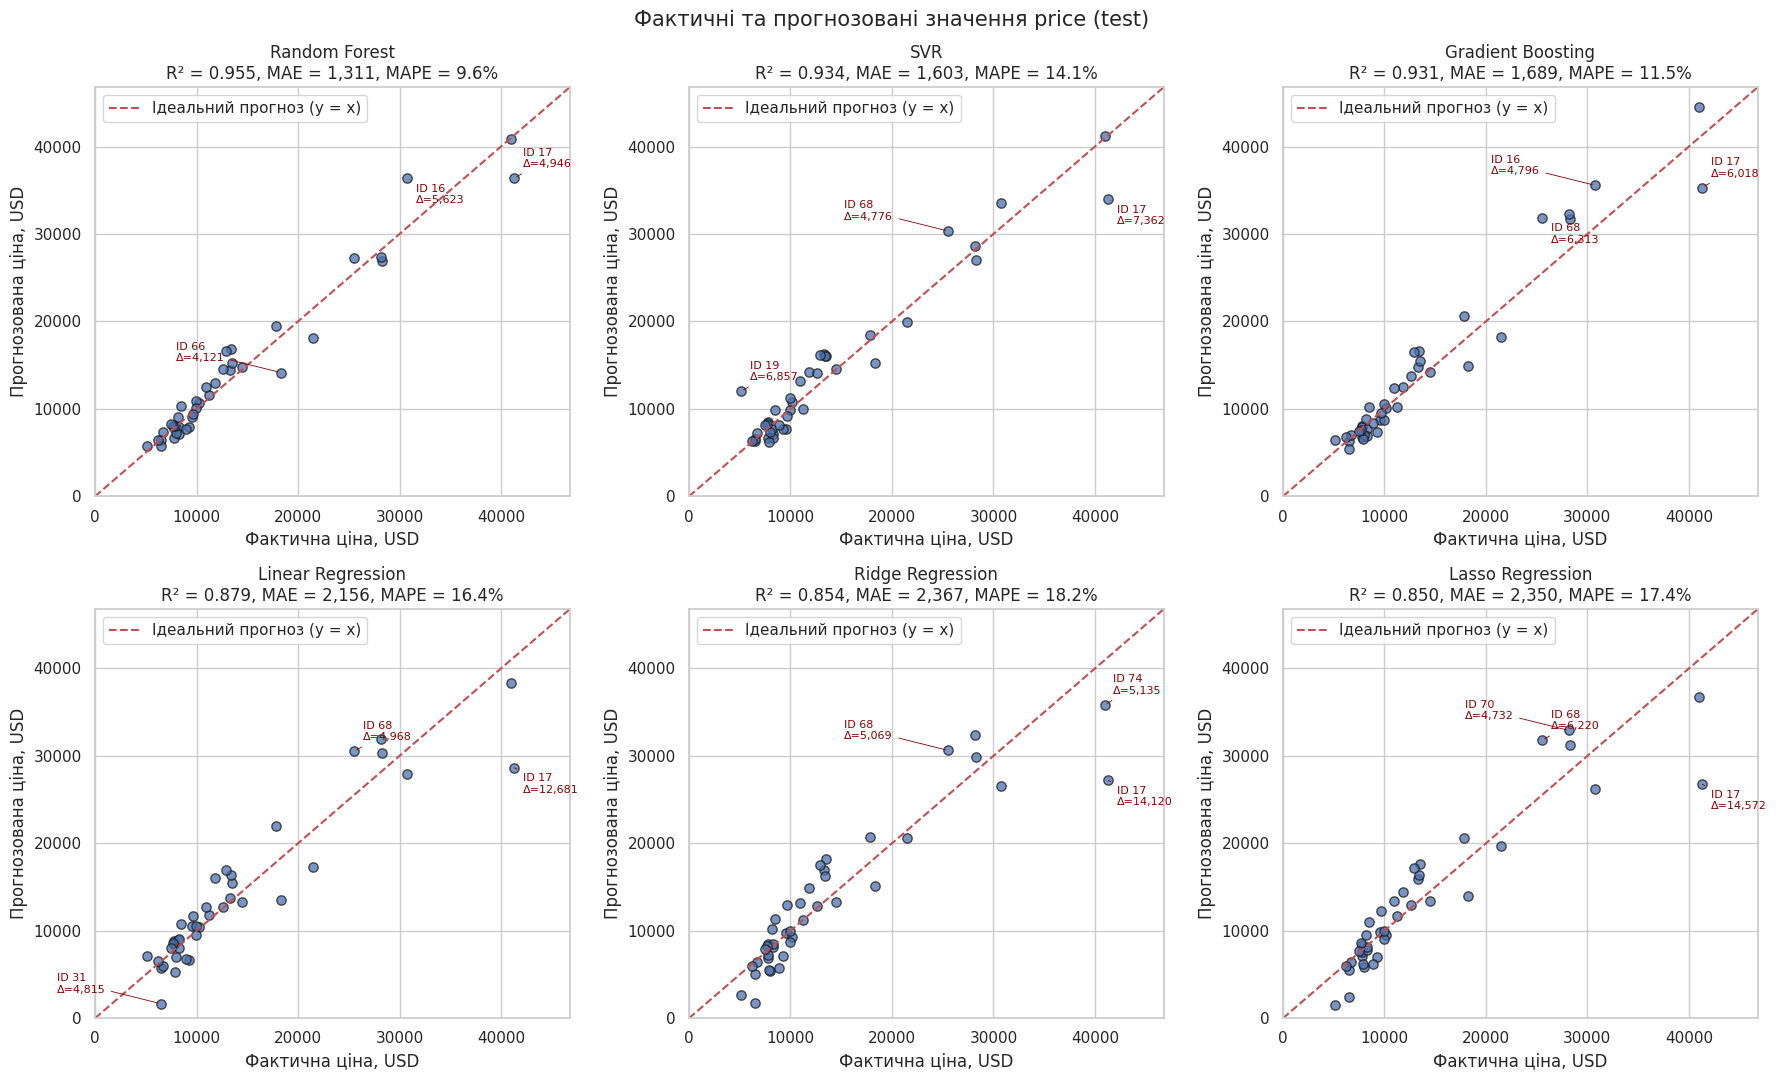

,Модель,car_ID з найбільшими помилками,Абсолютні помилки
0,Random Forest,"[16, 17, 66]","[5623, 4946, 4121]"
1,SVR,"[17, 19, 68]","[7362, 6857, 4776]"
2,Gradient Boosting,"[68, 17, 16]","[6313, 6018, 4796]"
3,Linear Regression,"[17, 68, 31]","[12681, 4968, 4815]"
4,Ridge Regression,"[17, 74, 68]","[14120, 5135, 5069]"
5,Lasso Regression,"[17, 68, 70]","[14572, 6220, 4732]"


Найдорожчі автомобілі тестової вибірки:


,car_ID,brand,price
25,17,bmw,"41,315.000"
14,74,buick,"40,960.000"
0,16,bmw,"30,760.000"
4,69,buick,"28,248.000"
35,70,buick,"28,176.000"


In [37]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
lims = [0, max(y_test.max(), max(p.max() for p in predictions.values())) * 1.05]
offsets = [(-75, 8), (6, 8), (6, -18)]

for ax, name in zip(axes.ravel(), results_df['Модель']):
    y_pred = predictions[name]
    abs_err = np.abs(y_test.to_numpy() - y_pred)
    ax.scatter(y_test, y_pred, alpha=0.75, edgecolor='k', s=45)
    ax.plot(lims, lims, 'r--', lw=1.5, label='Ідеальний прогноз (y = x)')
    for k, j in enumerate(np.argsort(abs_err)[-3:]):
        ax.annotate(f'ID {id_test.iloc[j]}\nΔ={abs_err[j]:,.0f}', (y_test.iloc[j], y_pred[j]),
                    textcoords='offset points', xytext=offsets[k], fontsize=8, color='darkred',
                    arrowprops=dict(arrowstyle='-', color='darkred', lw=0.6))
    r = results_df.set_index('Модель').loc[name]
    ax.set_title(f'{name}\nR² = {r["R²"]:.3f}, MAE = {r["MAE"]:,.0f}, MAPE = {r["MAPE, %"]:.1f}%')
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel('Фактична ціна, USD')
    ax.set_ylabel('Прогнозована ціна, USD')
    ax.legend(loc='upper left')
plt.suptitle('Фактичні та прогнозовані значення price (test)', fontsize=15)
plt.tight_layout()
plt.show()

largest = []
for name in results_df['Модель']:
    err = pd.Series(np.abs(y_test.to_numpy() - predictions[name]), index=id_test.to_numpy())
    top = err.sort_values(ascending=False).head(3)
    largest.append({'Модель': name, 'car_ID з найбільшими помилками': list(top.index),
                    'Абсолютні помилки': [round(v) for v in top.values]})
display(pd.DataFrame(largest))
test_view = pd.DataFrame({'car_ID': id_test.to_numpy(), 'brand': X_test['brand'].to_numpy(),
                          'price': y_test.to_numpy()})
print('Найдорожчі автомобілі тестової вибірки:')
display(test_view.sort_values('price', ascending=False).head(5))

**Висновок до п. 13.**
- **Найближче до лінії ідеального прогнозу** точки Random Forest, SVR і Gradient Boosting, для лінійних моделей розкид помітно більший. Для дешевих і середніх авто (до ~20 тис. USD), яких у даних більшість, прогнози найточніші. Зі зростанням ціни розкид збільшується, бо дорогих авто в train мало (12 з ціною понад 30 тис. USD).
- **Найбільше відхилення — `car_ID` 17** (BMW, 41 315 USD): його недооцінюють усі моделі — RF на ≈ 4.9 тис., GB на ≈ 6.0 тис., SVR на ≈ 7.4 тис., лінійні на 12.7–14.6 тис. USD. У тестовій вибірці є ще `car_ID` 16 (BMW, 30 760 USD) з такими самими `enginesize` = 209 і `horsepower` = 182: Random Forest і Gradient Boosting дають обом авто ≈ 35–36 тис. USD, і для ID 16 це переоцінка. Наявні ознаки ці дві моделі (BMW X4 і X5) практично не розрізняють, тож частина помилки неусувна за цих даних.
- **Лінійні моделі для кількох дешевих авто дають нереалістично низькі прогнози.** Для `car_ID` 31 (Honda, 6 479 USD) Linear Regression прогнозує ≈ 1.7 тис. USD — це наслідок лінійної екстраполяції.
- **SVR сильно переоцінює `car_ID` 19** (Chevrolet, 5 151 → ≈ 12 тис. USD). Це єдине авто з категорією `cylindernumber = 'three'`, якої немає в train.
- **Систематичної помилки в ансамблів не видно:** точки розташовані по обидва боки від діагоналі.


## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [38]:
rf_pipe = pipelines['Random Forest']
sample_pos = np.random.RandomState(RANDOM_STATE).choice(len(X_test), size=10, replace=False)
X_sample = X_test.iloc[sample_pos]
y_sample = y_test.iloc[sample_pos]
pred_sample = rf_pipe.predict(X_sample)

sample_table = pd.DataFrame({
    'car_ID': id_test.iloc[sample_pos].to_numpy(),
    'Марка': X_sample['brand'].to_numpy(),
    'Фактична ціна': y_sample.to_numpy(),
    'Прогнозована ціна': pred_sample,
})
sample_table['Абсолютна помилка'] = (sample_table['Фактична ціна'] - sample_table['Прогнозована ціна']).abs()
sample_table['Абсолютна відсоткова помилка, %'] = (sample_table['Абсолютна помилка']
                                                   / sample_table['Фактична ціна'] * 100)
display(sample_table.style.format({'Фактична ціна': '{:,.0f}', 'Прогнозована ціна': '{:,.0f}',
                                   'Абсолютна помилка': '{:,.0f}',
                                   'Абсолютна відсоткова помилка, %': '{:.2f}'}))
print(f"Середня абсолютна помилка для 10 авто: {sample_table['Абсолютна помилка'].mean():,.0f} USD")
print(f"Середня абсолютна відсоткова помилка: {sample_table['Абсолютна відсоткова помилка, %'].mean():.2f}%")
print(f"Медіанна абсолютна відсоткова помилка: {sample_table['Абсолютна відсоткова помилка, %'].median():.2f}%")
print(f"Авто з помилкою < 10%: {(sample_table['Абсолютна відсоткова помилка, %'] < 10).sum()} з 10")

,car_ID,Марка,Фактична ціна,Прогнозована ціна,Абсолютна помилка,"Абсолютна відсоткова помилка, %"
0,26,dodge,"6,692","7,322",630,9.42
1,176,toyota,"9,988","10,929",941,9.42
2,148,subaru,"10,198","10,695",497,4.88
3,17,bmw,"41,315","36,369","4,946",11.97
4,69,buick,"28,248","26,910","1,338",4.74
5,147,subaru,"7,463","8,294",831,11.14
6,144,subaru,"9,960","10,063",103,1.03
7,85,mitsubishi,"14,489","14,826",337,2.32
8,195,volvo,"12,940","16,563","3,623",28.00
9,160,toyota,"7,788","7,827",39,0.50


Середня абсолютна помилка для 10 авто: 1,329 USD
Середня абсолютна відсоткова помилка: 8.34%
Медіанна абсолютна відсоткова помилка: 7.15%
Авто з помилкою < 10%: 7 з 10


**Висновок до п. 14.** Для 10 випадкових авто з test середня абсолютна помилка Random Forest ≈ **1 329 USD**, середня відсоткова ≈ **8.3%** (медіана 7.2%). У 7 з 10 авто похибка менша за 10%, що відповідає загальній MAPE моделі на test (9.6%).
- **Найточніші прогнози:** `car_ID` 160 (Toyota, 0.5%), 144 (Subaru, 1.0%), 85 (Mitsubishi, 2.3%) — масові недорогі моделі, яких у train багато.
- **Найбільша відсоткова помилка — `car_ID` 195** (Volvo, 12 940 → 16 563 USD, 28%): у train усі Volvo коштують 15 985–22 625 USD, і модель «підтягує» прогноз до типової ціни марки.
- **Найбільша абсолютна помилка — `car_ID` 17** (BMW, 41 315 → 36 369 USD, −4 946 USD, 12%): дороге авто недооцінене, оскільки ансамбль дерев усереднює ціни подібних, але дешевших авто і не екстраполює за межі навчальних значень.


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


**Підсумкові висновки**

1. **Порівняння моделей.** На тестовій вибірці (41 авто) найкращу якість за всіма метриками показав **Random Forest**: R² = 0.955, MAE ≈ 1.31 тис. USD, MSE ≈ 3.5 млн, MAPE ≈ 9.6%. Далі йдуть SVR (R² 0.934, MAPE 14.1%) і Gradient Boosting (R² 0.931, MAPE 11.5%). Лінійні моделі (Linear, Ridge, Lasso) суттєво поступаються: R² 0.85–0.88, MAE 2.2–2.4 тис. USD, MAPE 16–18%. Нелінійні моделі краще описують залежність ціни від характеристик (взаємодії марки, потужності, маси й типу двигуна).

2. **Аналіз метрик.**
   - R² ≈ 0.93–0.96 у найкращих моделей означає, що вони пояснюють 93–96% варіації ціни на test.
   - MAE ≈ 1.3–1.7 тис. USD при середній ціні ≈ 13.5 тис. USD — це типова похибка ≈ 10–13% ціни.
   - MSE (і RMSE ≈ 1.9–2.3 тис. USD) значно чутливіша до поодиноких великих помилок: для лінійних моделей одне дороге авто (`car_ID` 17) дає понад 40% MSE.
   - MAPE показує відносну похибку і краще відображає якість для дешевих авто. Саме за нею Gradient Boosting випереджає SVR, хоча за R² і MAE поступається.

3. **Величина похибок.** Найменші похибки — для дешевих і середніх авто, яких у даних більшість. Найбільші — для дорогих і рідкісних моделей (BMW, Buick, Volvo з нетиповою ціною) та для авто з категорією, відсутньою в train (3-циліндровий Chevrolet). Для 10 випадкових авто Random Forest помиляється в середньому на ≈ 1.3 тис. USD (8.3%).

4. **Перенавчання.** У всіх моделей R² на train вищий, ніж на test: у ансамблів і SVR 0.985–0.996 проти 0.93–0.96, у лінійних 0.95–0.96 проти 0.85–0.88. Різниця помірна (0.03–0.10), критичного перенавчання немає. Найменший розрив — у Random Forest (0.03). Водночас R² на 5-кратній крос-валідації train нижчий (0.87–0.89 для найкращих моделей), тож результат на одному малому test дещо оптимістичний. Реалістична очікувана якість — R² ≈ 0.87–0.9. Ridge і Lasso на крос-валідації стабільніші за звичайну лінійну регресію, отже регуляризація зменшує ризик перенавчання.

5. **Вплив попередньої обробки.**
   - Обмеження викидів межами train зберегло всі 164 об'єкти навчальної вибірки (30% рядків містили викиди) і зменшило вплив екстремальних значень.
   - Yeo–Johnson знизив середню |skew| неперервних ознак з 0.92 до 0.02, що особливо важливо для лінійних моделей і SVR.
   - Масштабування зробило ознаки сумірними, без чого регуляризація Ridge/Lasso і RBF-ядро SVR працюють некоректно.
   - Кореляційний відбір прибрав 4 дублюючі ознаки й зменшив мультиколінеарність.
   - Заміна `CarName` на виправлену марку `brand` дала моделям важливу інформацію про бренд без сотні розріджених стовпців.
   - One-Hot з `handle_unknown='ignore'` коректно обробив нову категорію в test.
   - Усі параметри передобробки визначались тільки за train у складі Pipeline, тому отримані метрики є чесною оцінкою якості на нових даних.

Для подальшого покращення доцільно підібрати гіперпараметри (GridSearchCV на train), спробувати логарифмування `price` і зібрати більше даних про дорогі автомобілі.


## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
